# Init:

In [234]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


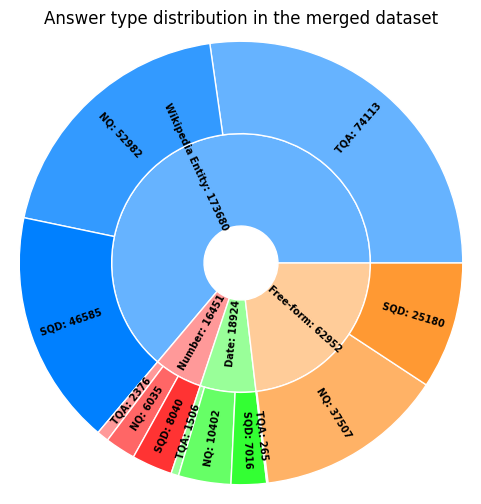

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [4]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [44]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.cluster_questions import *

In [53]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [167]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_numerical_values(num_data)
date_clusters = cluster_date_values(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)} with mean cluster size of: {np.mean([len(value) for value in ent_clusters.values()]):.2f}')
print(f'Numerical: {len(num_clusters)} with mean cluster size of: {np.mean([len(value) for value in num_clusters.values()]):.2f}')
print(f'Date & Time: {len(date_clusters)} with mean cluster size of: {np.mean([len(value) for value in date_clusters.values()]):.2f}')

Total candidate clusters:
Entities: 24719 with mean cluster size of: 5.36
Numerical: 15 with mean cluster size of: 1096.73
Date & Time: 960 with mean cluster size of: 19.18


## 3.1 - Cluster and filter entity questions:

In [189]:
from knowledge_maze.create_dataset.create_reasoning_path import generate_question_embeddings
# Generate embeddings for all entity questions:
entity_questions_embeddings = generate_question_embeddings(ent_clusters, batch_size=2048)
# Filter questions based on similarity graph:
filtered_entity_clusters = filter_question_groups(ent_clusters, entity_questions_embeddings)
# Split question clusters to a maximum size of 10:
entity_reasoning_chains = split_clusters(filtered_entity_clusters)

Generating question embeddings: 100%|██████████████████████████████████████████████████| 65/65 [03:07<00:00,  2.89s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 24719/24719 [00:15<00:00, 1558.05it/s]
Splitting large clusters: 100%|█████████████████████████████████████████████| 24719/24719 [00:00<00:00, 1021196.34it/s]


In [212]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\entity_reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(entity_reasoning_chains, out_file)

In [214]:
# Load from folder:
entity_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

## 3.2 - Create numerical questions reasoning paths:

In [187]:
from knowledge_maze.create_dataset.create_reasoning_path import generate_question_embeddings, filter_question_groups, split_clusters
# Generate embeddings for all entity questions:
numerical_questions_embeddings = generate_question_embeddings(num_clusters, batch_size=2048)
# Filter questions based on similarity graph:
filtered_num_clusters = filter_question_groups(num_clusters, numerical_questions_embeddings)
# Split question clusters to a maximum size of 10:
numerical_reasoning_chains = split_clusters(filtered_num_clusters)

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:26<00:00,  2.98s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 15/15 [00:30<00:00,  2.03s/it]
Splitting large clusters: 100%|██████████████████████████████████████████████████████| 15/15 [00:00<00:00, 1221.12it/s]


In [215]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(numerical_reasoning_chains, out_file)

In [216]:
# Load from folder:
numerical_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

## 3.3 - Create date & time questions reasoning paths:

In [188]:
from knowledge_maze.create_dataset.create_reasoning_path import generate_question_embeddings, filter_question_groups, split_clusters
# Generate embeddings for all entity questions:
date_questions_embeddings = generate_question_embeddings(date_clusters, batch_size=2048)
# Filter questions based on similarity graph:
filtered_date_clusters = filter_question_groups(date_clusters, date_questions_embeddings)
# Split question clusters to a maximum size of 10:
date_reasoning_chains = split_clusters(filtered_date_clusters)

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:25<00:00,  2.83s/it]
Creating similarity graphs and filtering questions: 100%|███████████████████████████| 960/960 [00:01<00:00, 510.83it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████| 960/960 [00:00<00:00, 272911.20it/s]


In [217]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\date_reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(date_reasoning_chains, out_file)

In [218]:
# Load from folder:
date_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

## 3.4 - Show clusters distribution & display graph examples:

In [239]:
# Merge & save all clusters into one dataset:
reasoning_chains = list(np.concatenate([entity_reasoning_chains, numerical_reasoning_chains, date_reasoning_chains]))
output_path = f"{REPO_PATH}\data_files\\reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(reasoning_chains, out_file)

In [240]:
# Load from folder:
reasoning_chains = load_json(f"{REPO_PATH}\data_files\\reasoning_chains.json")

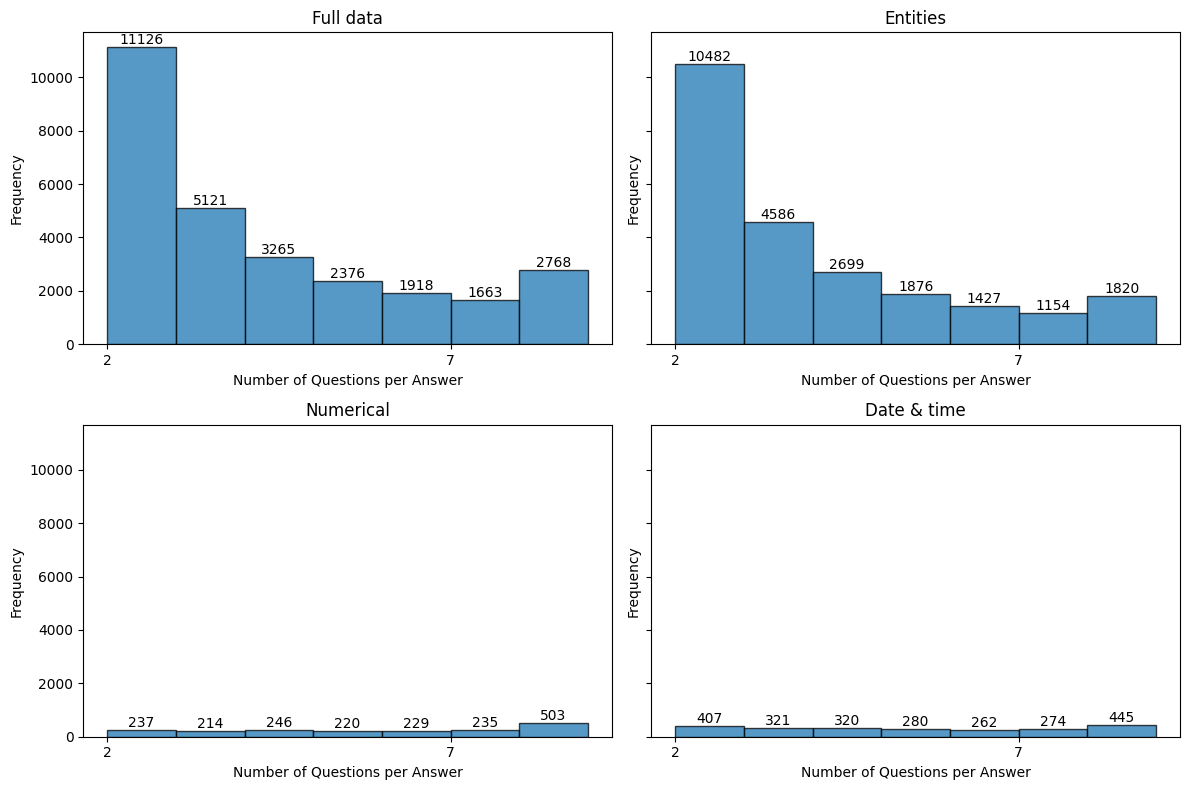

In [245]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution
plot_clusters_distribution({
    'Full data': reasoning_chains,
    'Entities': entity_reasoning_chains,
    'Numerical': numerical_reasoning_chains,
    'Date & time': date_reasoning_chains
})

In [232]:
from random import choice
# Plot random clusters:
print('=' * 50)
print('Entitity Cluster:')
print('=' * 50)
ent_sample = choice(entity_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Numerical Cluster:')
print('=' * 50)
ent_sample = choice(numerical_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Date & time Cluster:')
print('=' * 50)
ent_sample = choice(date_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)

Entitity Cluster:
Answer: Naphtali Daggett
List of questions:
- Who was the professor of Yale Divinity School that led the student militia to confront the Redcoats?
- The militia that fought in New Haven was lead by who? 
Numerical Cluster:
Answer: [11, 50]
List of questions:
- How many code positions were left unassigned for furture standardization?
- What is the maximum length of a runway?
- How many possible points are there for rhythmic routines?
Date & time Cluster:
Answer: ['year', 1784]
List of questions:
- In what year did Ben Franklin write a satire suggesting firing cannons at sunrise to wake people up?
- When was the African Lodge, number 459, formed?
- What year was the first Paris department store founded? 
- When did Britain pass Pitt's India Act?


Answer: Dreadnought
Questions before filtering:
1. In February 1906, which type of British battleship was launched for the first time?
2. What is a big acoustic guitar, a type of old battleship, and a thick coat cloth, which means 'fear nothing'?
3. What name was given to the predominant type of 20th-century battleship, with an 'all-big-gun' armament & steam turbine propulsion, that was named after the first of the kind, launched by the Royal Navy in 1906?


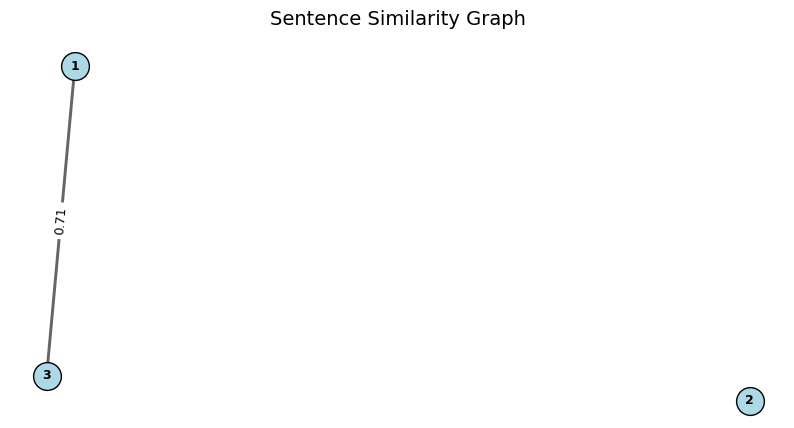

Questions after filtering:
1. What is a big acoustic guitar, a type of old battleship, and a thick coat cloth, which means 'fear nothing'?
2. What name was given to the predominant type of 20th-century battleship, with an 'all-big-gun' armament & steam turbine propulsion, that was named after the first of the kind, launched by the Royal Navy in 1906?


In [225]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(ent_clusters, entity_questions_embeddings)

# 4. Create paragraphs:

In [267]:
from knowledge_maze.tools.api_tools import *
import asyncio

# Define the system prompt
system_prompt = "You are an expert assistant that provides concise and factual answers."

# Initialize the GPT API client
gpt_client = gptAPI(system_prompt=system_prompt, model="gpt-4o-mini")

# Example queries
queries = [
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "Describe the history of the Roman Empire in 3 sentences.",
    "Describe the history of the Roman Empire in 3 sentences.",
    "Describe the history of the Roman Empire in 3 sentences.",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
]

# Run asynchronously and track usage
results = await gpt_client.async_run(queries)

# Display the results
for i, response in enumerate(results):
    print(f"Response {i + 1}: {response}")

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 27/27 [00:17<00:00,  1.56it/s]

Response 1: The capital of France is Paris.
Response 2: The theory of relativity, developed by Albert Einstein, consists of two main parts: special relativity and general relativity.

1. **Special Relativity** (1905): This part focuses on how time and space are linked for objects moving at constant speeds, especially those close to the speed of light. Key ideas include:
   - **Time Dilation**: Time moves slower for objects moving very fast compared to stationary observers. For example, if you travel in a spaceship at near-light speed, you would age more slowly than people on Earth.
   - **Length Contraction**: Objects moving at high speeds appear shorter in the direction of motion to a stationary observer.
   - **Mass-Energy Equivalence**: Expressed in the famous equation E=mc², it shows that mass can be converted into energy and vice versa.

2. **General Relativity** (1915): This part expands the theory to include gravity. It describes gravity not as a force, but as a curvature of spa

In [ ]:
{
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}

In [273]:
import random

def process_data_to_list(db: list[dict]) -> list[dict]:
    """
    Processes the input database into a list of dictionaries, each containing
    a randomly chosen question, its answer, and two reasoning paths.

    Args:
        db (list[dict]): List of dictionaries containing answers and corresponding questions.

    Returns:
        list[dict]: A list where each dictionary contains:
            - 'Question': The main question.
            - 'Answer': The associated answer.
            - 'Reasoning path 1': A chain of reasoning sub-questions (partition 1).
            - 'Reasoning path 2': A chain of reasoning sub-questions (partition 2).
    """
    results = []

    for cluster in db:
        questions = cluster['Questions']
        answer = cluster['Answer']

        # Randomly select a question to be the main question
        main_question = random.choice(questions)
        questions.remove(main_question)

        # Partition the remaining questions into two reasoning paths
        random.shuffle(questions)
        split_point = random.randint(1, len(questions) - 1) if len(questions) > 1 else 1
        path1_questions = questions[:split_point]
        path2_questions = questions[split_point:]

        # Generate reasoning paths with chained sub-questions
        def create_reasoning_path(path_questions):
            path = []
            previous_sub_question = main_question
            for question in path_questions:
                path.append({
                    'Previous Sub-question': previous_sub_question,
                    'Next Sub-question': question,
                    'Paragraph': None
                })
                previous_sub_question = question
            return path

        reasoning_path_1 = create_reasoning_path(path1_questions)
        reasoning_path_2 = create_reasoning_path(path2_questions)

        # Create the result dictionary for this cluster
        result = {
            'Question': main_question,
            'Answer': answer,
            'Reasoning path 1': reasoning_path_1,
            'Reasoning path 2': reasoning_path_2
        }
        results.append(result)

    return results

In [279]:
entity_reasoning_chains[:4]

[{'Answer': 'Jane Russell',
  'Questions': ['Which hollywood sex symbol, star of Gentlemen Prefer Blondes, died in 2011, aged 89?',
   "who starred with marilyn monroe in diamonds are a girl's best friend",
   'who played seven of nine in star trek',
   'who wrote sitting on top of the world',
   'Ant & Dec first appeared on TV together in which series?',
   'Charles Fortnum is the eponymous character in whose 1973 novel The Honorary Consul?',
   'who is rodrigo in mozart in the jungle',
   'What was halted with the torch relay for future Olympics?',
   "who sings. in case you didn't know",
   'Graham McPherson achieved fame as a singer using which name?']},
 {'Answer': "Ford's Theatre",
  'Questions': ['In what theater was Abraham Lincoln shot?',
   'Now a National Historic Site, at what Washington DC location (10th St NW) did the first presidential assassination take place?',
   'In Arthurian legend, what name is given to the sunken land believed to lie off the Isles of Scilly?',
   

In [277]:
process_data_to_list(entity_reasoning_chains[5:8])

[{'Question': "What era were the mosaics that adorned Saint Catherine's Monastery?",
  'Answer': 'Property crime',
  'Reasoning path 1': [{'Previous Sub-question': "What era were the mosaics that adorned Saint Catherine's Monastery?",
    'Next Sub-question': 'when did the sat score change to 2400',
    'Paragraph': None},
   {'Previous Sub-question': 'when did the sat score change to 2400',
    'Next Sub-question': 'who played carlton on fresh prince of bel-air',
    'Paragraph': None},
   {'Previous Sub-question': 'who played carlton on fresh prince of bel-air',
    'Next Sub-question': 'who identified the tube connecting the ear and throat',
    'Paragraph': None}],
  'Reasoning path 2': [{'Previous Sub-question': "What era were the mosaics that adorned Saint Catherine's Monastery?",
    'Next Sub-question': 'who does the voices of the minions in despicable me',
    'Paragraph': None},
   {'Previous Sub-question': 'who does the voices of the minions in despicable me',
    'Next Sub-